# 02 — Feature engineering

This notebook converts the adjusted closing prices from Notebook 1 into the features used by the sector-allocation agent.

In [ ]:
from pathlib import Path
import sys

project_root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "src" / "portfolio_rl" / "data.py").is_file()
)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import matplotlib.pyplot as plt
import pandas as pd
import yaml

from src.portfolio_rl.data import (
    ASSET_FEATURES, SPY_FEATURES, MARKET_FEATURES,
    build_market_features, sort_market_data,
)
from src.portfolio_rl.validation import (
    FEATURE_BOUNDS, FEATURE_WARMUP_PERIODS, validate_feature_data,
)


## Load and prepare the market data

In [ ]:
RAW_PATH = project_root / "data" / "raw" / "yahoo_daily_adjusted.csv.gz"
config = yaml.safe_load((project_root / "configs" / "long_only.yaml").read_text())
tradable_symbols = config["data"]["tradable_symbols"]
market_data = sort_market_data(pd.read_csv(RAW_PATH, parse_dates=["date"]))
market_data.head()


## Price features

Price-based feature calculations are shared with the application in
`src/portfolio_rl/data.py` and covered by `tests/test_features.py`.


## Relative and market features

Market-relative and cross-sectional calculations use the same shared functions.
The configured tradable universe comes from `configs/long_only.yaml`.


## Market-regime features

`build_market_features` validates raw observations before calculating any
features, then validates the completed feature table before returning it.


## Create the feature dataset

In [ ]:
featured_data = build_market_features(market_data, tradable_symbols)


In [ ]:
feature_columns = list(FEATURE_WARMUP_PERIODS)
featured_data[["date", "symbol", *feature_columns]].tail()


In [ ]:
# Construction already validated values and allowed only declared feature warm-up.
tradable_data = featured_data.loc[featured_data["tradable"]]
complete_dates = tradable_data.groupby("date")[feature_columns].apply(
    lambda values: values.notna().all().all()
)
first_complete_date = complete_dates[complete_dates].index[0]
complete_data = tradable_data.loc[tradable_data["date"] >= first_complete_date]

print(f"All tradable features are complete from {first_complete_date.date()}.")
display(complete_data[["date", "symbol", *feature_columns]].groupby("symbol").tail(1))


## Inspect the engineered features

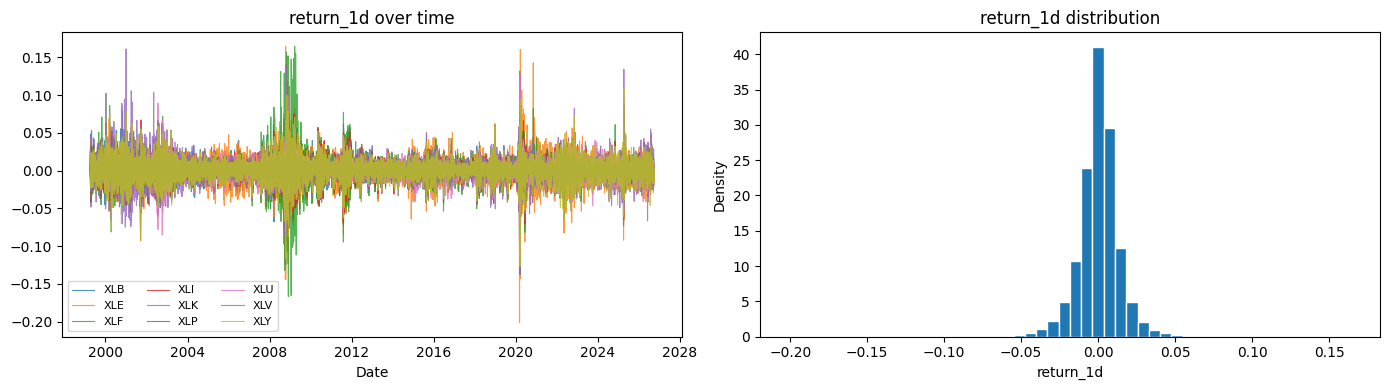

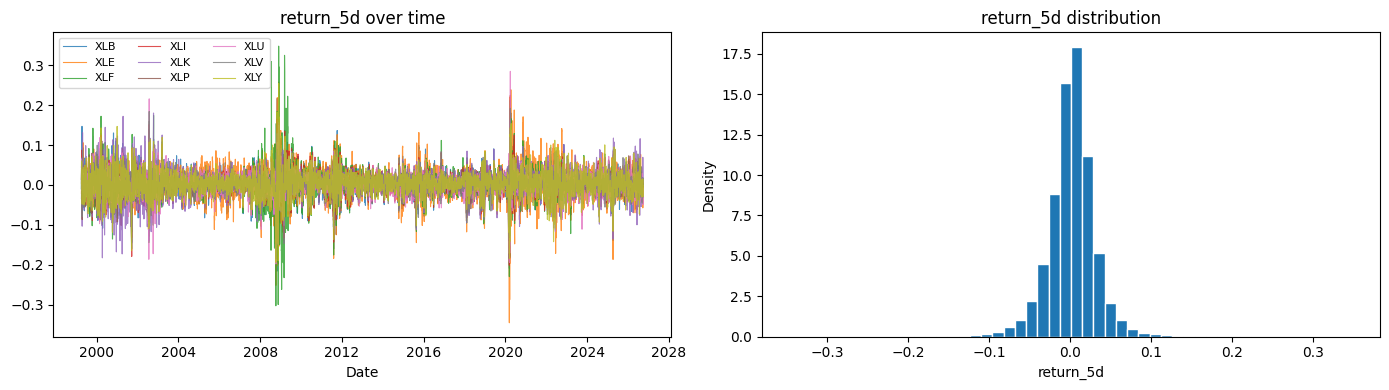

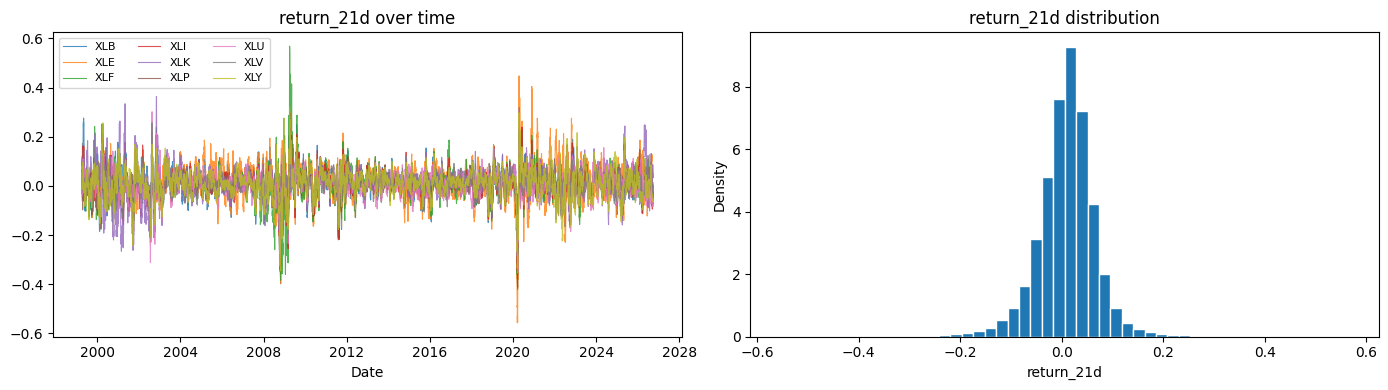

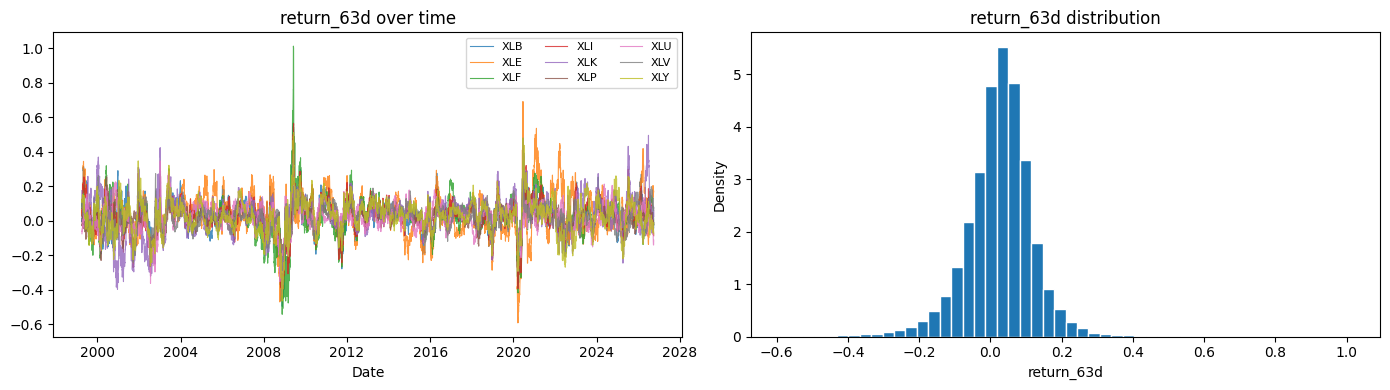

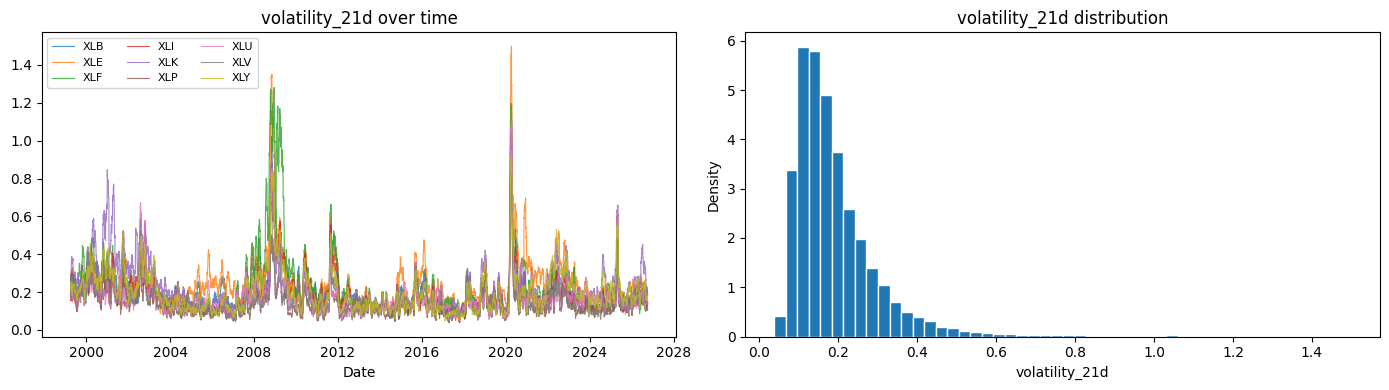

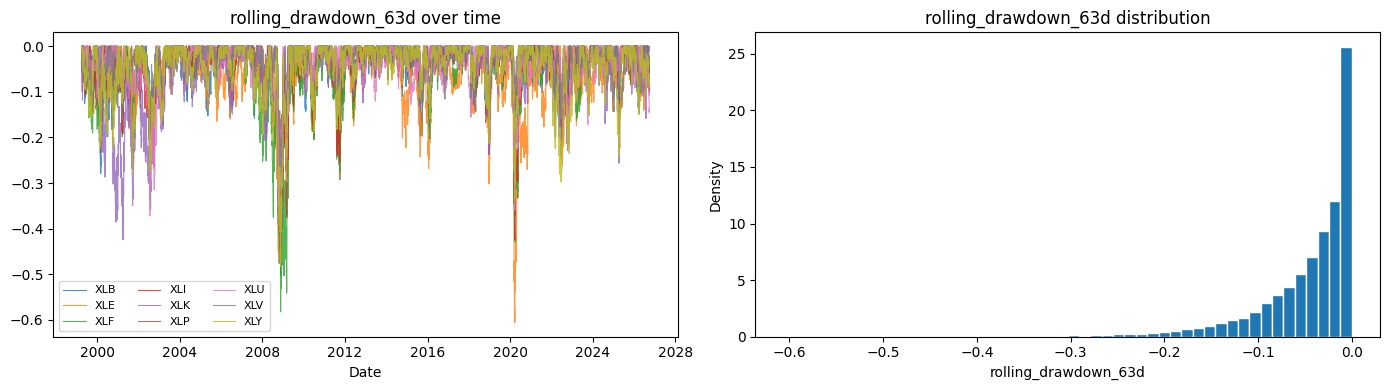

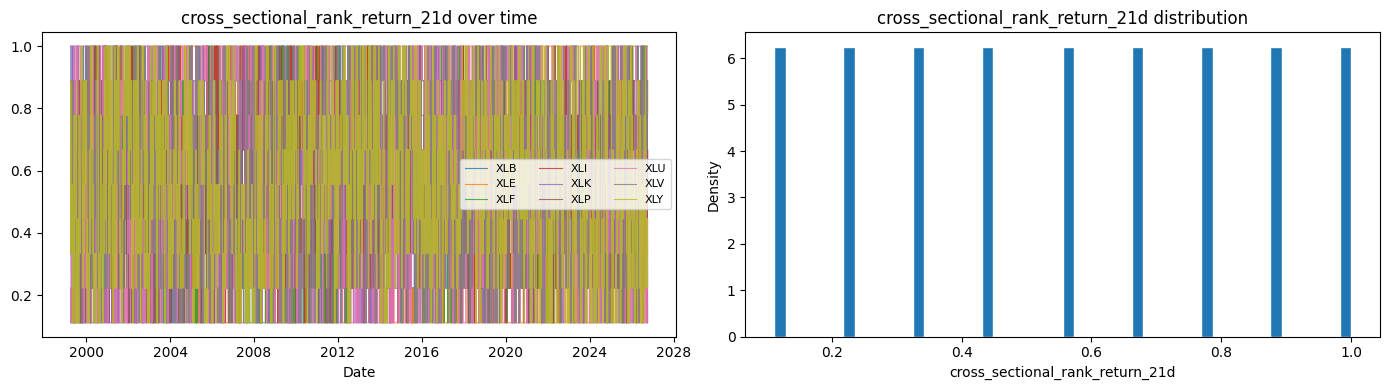

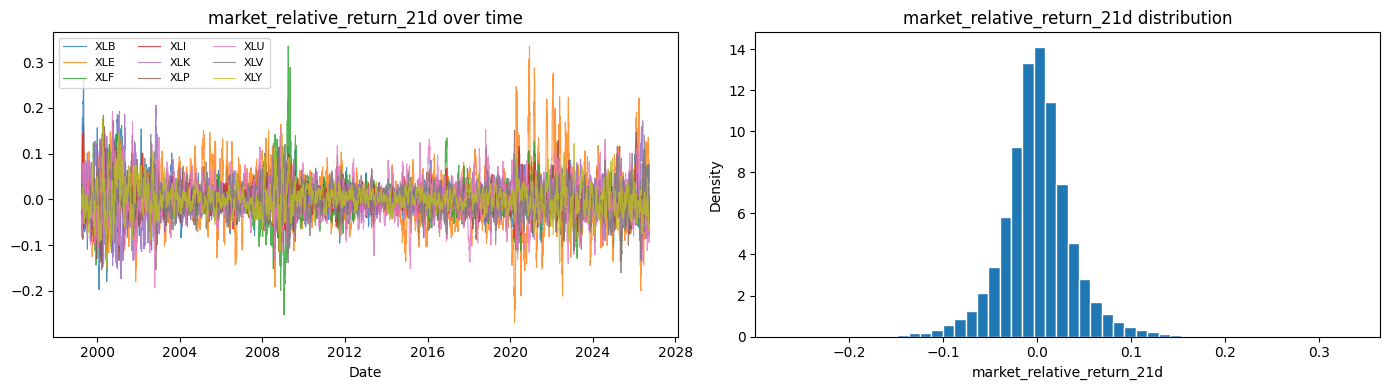

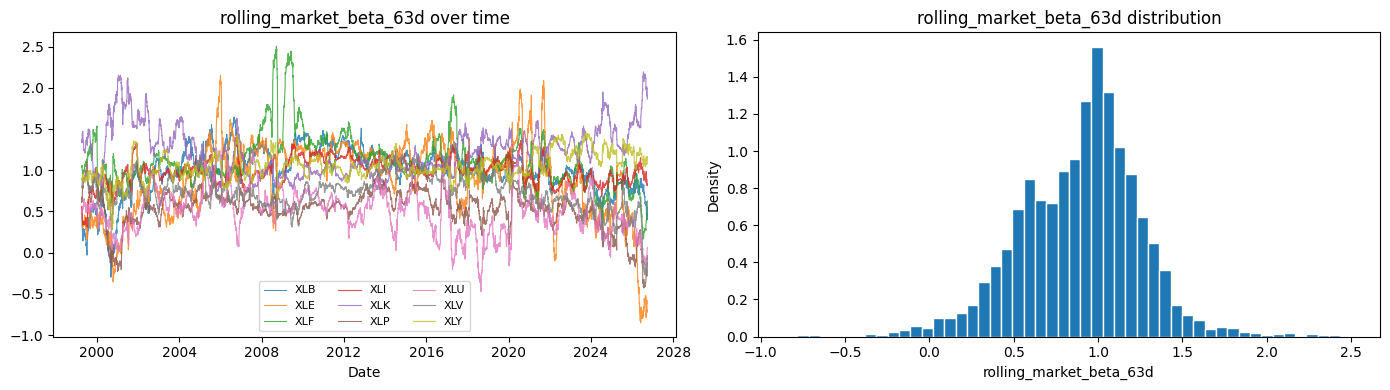

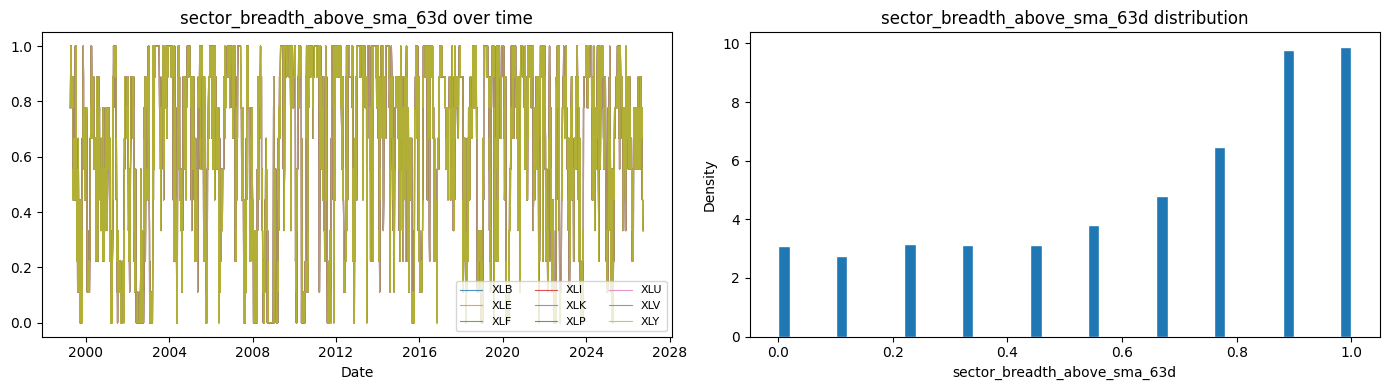

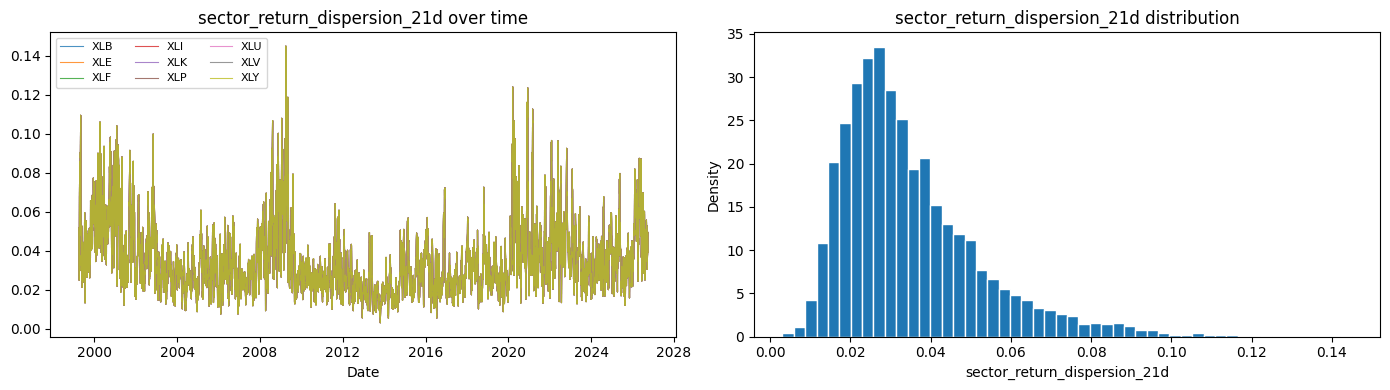

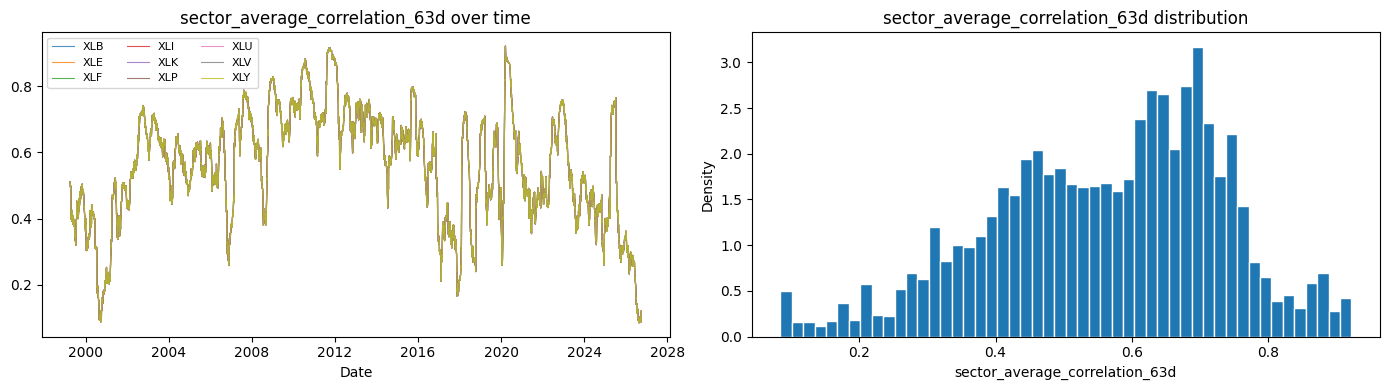

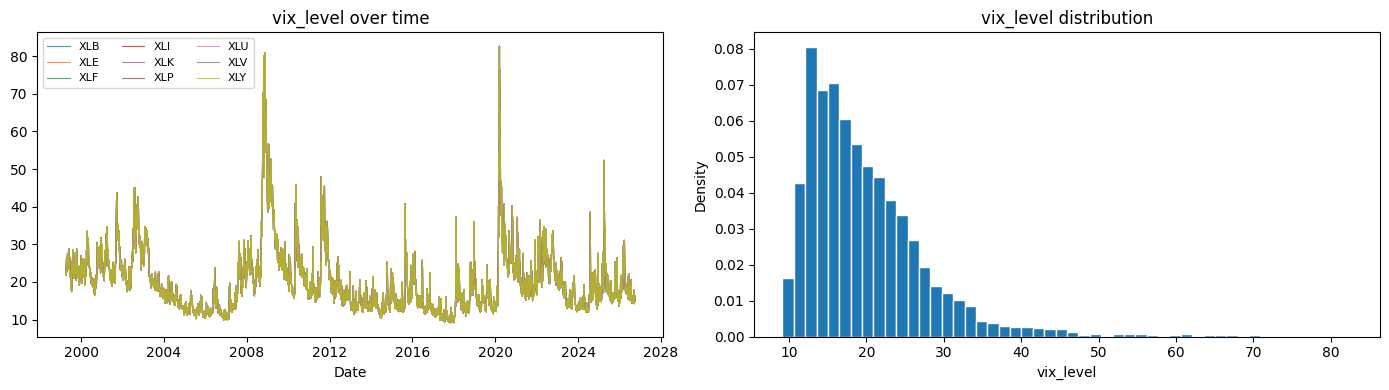

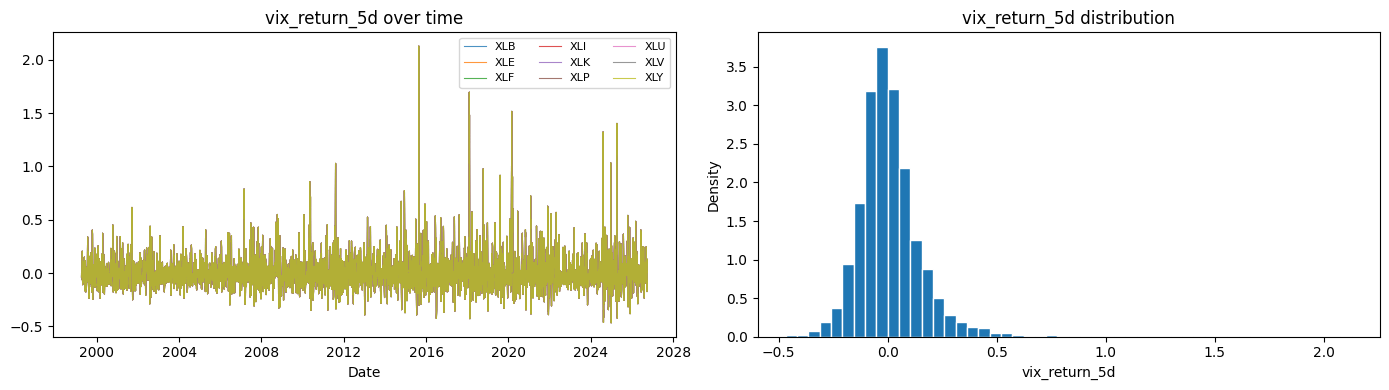

In [9]:
for feature in feature_columns:
    figure, axes = plt.subplots(1, 2, figsize=(14, 4))

    for symbol, observations in complete_data.groupby("symbol"):
        axes[0].plot(
            observations["date"],
            observations[feature],
            label=symbol,
            linewidth=0.8,
            alpha=0.8,
        )

    axes[0].set_title(f"{feature} over time")
    axes[0].set_xlabel("Date")
    axes[0].legend(ncol=3, fontsize=8)

    axes[1].hist(
        complete_data[feature],
        bins=50,
        density=True,
        edgecolor="white",
    )
    axes[1].set_title(f"{feature} distribution")
    axes[1].set_xlabel(feature)
    axes[1].set_ylabel("Density")

    figure.tight_layout()
    plt.show()

## Save the feature dataset

In [ ]:
# Recheck immediately before writing, including SPY and market-context features.
validate_feature_data(
    featured_data, tradable_symbols, ASSET_FEATURES, SPY_FEATURES, MARKET_FEATURES,
    warmup_periods=FEATURE_WARMUP_PERIODS, feature_bounds=FEATURE_BOUNDS,
)

FEATURE_PATH = project_root / "data" / "processed" / "market_features.csv.gz"
FEATURE_PATH.parent.mkdir(parents=True, exist_ok=True)

featured_data.to_csv(FEATURE_PATH, index=False, compression="gzip")
print(f"Saved {len(featured_data):,} rows to {FEATURE_PATH}")

### Timing rule for the environment

Features observed on date $t$ determine the weights held over $t \rightarrow t+1$. The return realized over that interval must not be included in the date-$t$ observation.